In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import data
from datasets import load_dataset

ds = load_dataset("uoft-cs/cifar10")
train_loader, val_loader, test_loader = data.get_cifar10_loaders(ds)

In [5]:
import inspect
from pathlib import Path
import json
import pandas as pd
import torch
import models

CHECKPOINTS_DIR = Path("./checkpoints")
MODEL_KEYS = inspect.signature(models.ViTForClassification).parameters

def import_model(name):
    path = CHECKPOINTS_DIR / name
    with open(path / "config.json") as f:
        config = json.loads(f.read())
    
    history = pd.read_csv(path / "history.csv")
    steps_per_epoch = history.loc[history["val_loss"].notna(), "step"].iloc[0]
    history["epoch_frac"] = history["step"]/steps_per_epoch

    weigths = torch.load(path / "checkpoint.pth", weights_only=True)
    model = models.ViTForClassification(**{k: config[k] for k in MODEL_KEYS})
    model.load_state_dict(weigths)

    return model, history, config

dirs = ["vit-128-8L", "vit-128-8L-d", "vit-128-8L-d-cp4"]
data = [import_model(d) for d in dirs]
names = ["Base", "Dropout", "Dropout + Aug"]

runs = {
    name: {"model": model, "history": history, "config": config}
    for name, (model, history, config) in zip(names, data)
}

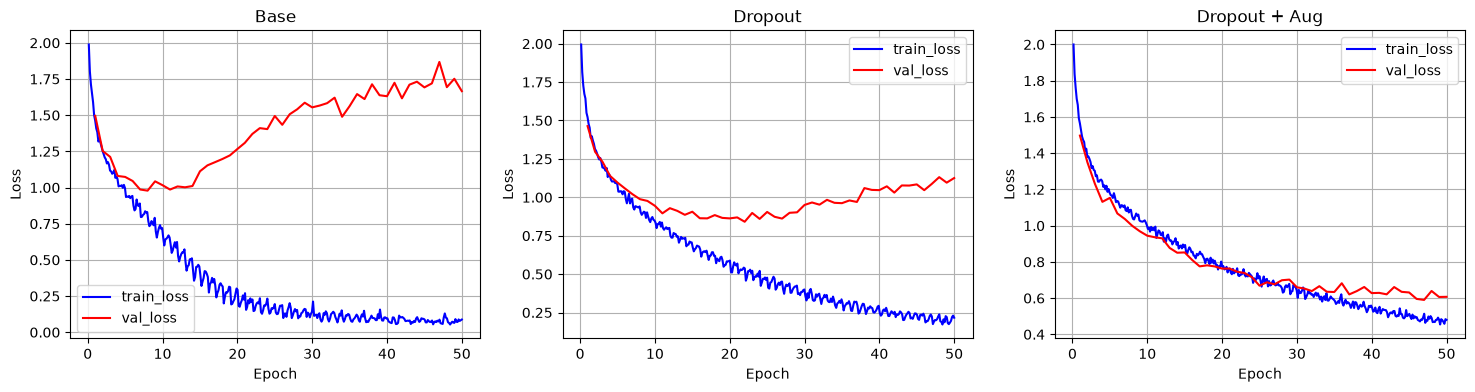

In [6]:
import matplotlib.pyplot as plt

def plot_train_eval(history, ax):
    ax.plot(history[history["train_loss"].notna()]["epoch_frac"], history["train_loss"].dropna(), color="blue", label="train_loss")
    ax.plot(history[history["val_loss"].notna()]["epoch"], history["val_loss"].dropna(), color="red", label="val_loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid()

fig, axs = plt.subplots(1, len(runs), figsize=(6*len(runs), 4))

for i, name in enumerate(runs):
    axs[i].set_title(name)
    plot_train_eval(runs[name]["history"], axs[i])

plt.show()

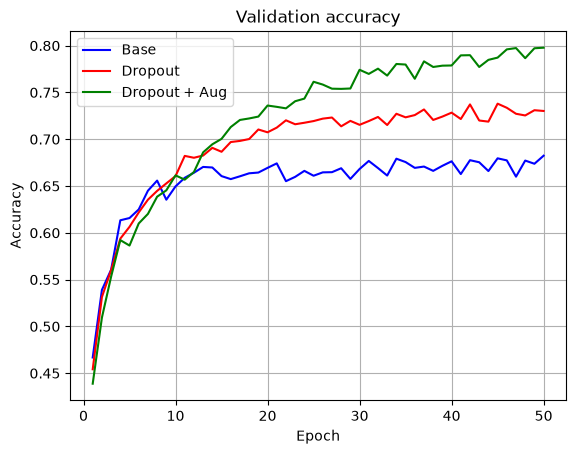

In [7]:
colors = ["blue", "red", "green"]

for name, col in zip(runs, colors):
    history = runs[name]["history"]
    plt.plot(history[history["val_acc"].notna()]["epoch"], history["val_acc"].dropna(), color=col, label=name)

plt.title("Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

In [8]:
import training

device = "mps" if torch.backends.mps.is_available() else "cpu"

test_results = [training.eval_classif(runs[name]["model"], test_loader, device) for name in runs]
df = pd.DataFrame([{"Test loss": loss, "Test accuracy": acc} for loss, acc in test_results])
df.index = runs.keys()
df

,Test loss,Test accuracy
Base,1.673932,0.6795
Dropout,1.164274,0.7160
Dropout + Aug,0.620825,0.7968


In [9]:
print(df.to_markdown(floatfmt=("", ".3f", ".1%")))

|               |   Test loss |   Test accuracy |
|:--------------|------------:|----------------:|
| Base          |       1.674 |           68.0% |
| Dropout       |       1.164 |           71.6% |
| Dropout + Aug |       0.621 |           79.7% |
